# 홈쇼핑 물류·배송 문의 유형 분류
### 고객이 처음 꺼낸 말 두 마디로 문의 유형을 자동으로 나누기 — TF-IDF + 분류 모델

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 2개)**
| 파일 | 내용 |
|---|---|
| 상담 대화 `.txt` 파일 | 홈쇼핑 콜센터 상담 대화 2,803건 (`[S20007]` 같은 번호 아래 `상담사:`/`고객:` 발화) |
| `inquiry_labels.csv` | 대화 번호별 **정답 문의 유형** (원래 파일에는 정답이 없어서 따로 만든 파일) |



## 오늘의 상황
> TV 홈쇼핑 콜센터에는 "방송 상품 주문", "배송은 언제 와요?", "주소 바꿔 주세요", "반품할게요" 같은 전화가 쉴 새 없이 들어옵니다.
> 고객이 **처음 두 마디**를 말했을 때 문의 유형을 자동으로 알아내면, 알맞은 상담 창구나 안내 화면으로 바로 연결할 수 있습니다.

## 분류할 문의 유형 (5개)
| 유형 | 예 |
|---|---|
| 상품 주문 | 방송 상품 주문, 가격·할인 카드·구성 문의, 자동 주문(ARS) 오류로 연결, 주문 전 배송 기간 문의 |
| 배송 조회·지연 | 언제 와요?, 아직 안 왔어요, 배송 완료라는데 못 받았어요, 사은품·구성품 미도착, 배송 날짜 조정 |
| 주소·주문 변경 | 이미 주문한 상품의 배송지·주소 변경, 주문 내역 확인, 색상·수량·받는 사람 변경, 회원 정보 수정 |
| 취소·반품·교환 | 주문 취소, 반품, 사이즈 교환, 불량·오배송 |
| 결제·기타 | 입금 확인, 결제 수단 변경, 결제 금액 오류, 적립금·쿠폰, 보험 상담 예약 등 그 밖의 문의 |

## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, 파일 2개 읽기 | 대화 수 |
| 1. 텍스트 전처리 | 대화 나누기 → 중복 확인 → **고객 질문 2마디** 뽑기 → 단어 나누기 | 대화 표 |
| 2. 정제 데이터셋 | 정답 붙이기, 유형 분포 확인, CSV 저장 | `inquiry_dataset.csv` |
| 3. 텍스트 분석 | 학습/평가 나누기 → TF-IDF → 분류 모델 3개 비교 | 학습된 모델 |
 | 4. 분석 결과 | 성적표, 혼동 행렬, 유형별 핵심 단어, 틀린 사례, **새 문의 넣어 보기** | 그래프, `predictions.csv` |
 | 정리 | 한계 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (단어 나누기) |
| `koreanize-matplotlib` | 그래프에 한글 글꼴(나눔고딕) 설정 |
| `scikit-learn` | TF-IDF, 분류 모델, 평가 (Colab에 기본 설치) |

In [1]:
# 도구 설치 (처음 한 번만 실행)
# !     : 파이썬 코드가 아니라 리눅스 명령어를 실행하라는 표시
# -q    : 설치 과정 메시지를 짧게 줄여서 보여 줌
!pip install -q kiwipiepy koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 9.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 88.0 MB/s eta 0:00:00


> 🔧 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 **상담 대화 `.txt` 파일**과 **`inquiry_labels.csv`** 를 끌어다 놓으세요.

In [4]:
import glob                 # 파일 이름을 패턴(예: *.txt)으로 찾는 도구
import pandas as pd         # 표(DataFrame)를 다루는 도구

# 지금 폴더에서 이름이 .txt로 끝나는 파일 목록을 찾아 첫 번째 파일을 고름
# (상담 대화 .txt 파일 하나만 올려 두세요)
txt_path = glob.glob("*.txt")[0]

# 대화 파일 전체를 하나의 긴 글자(문자열)로 읽기 (encoding="utf-8": 한글 파일 읽기 방식)
text = open(txt_path, encoding="utf-8").read()

# 정답 파일 읽기 → 열 2개(ID, 유형)짜리 표
labels = pd.read_csv("inquiry_labels_2.csv")

print("대화 파일:", txt_path)
print("정답 파일 행 수:", len(labels))

# 파일 앞부분 300글자만 잘라서 보기 ([:300] = 처음부터 300번째 글자 전까지)
print(text[:300])

대화 파일: K쇼핑_배송_대화내용.txt
정답 파일 행 수: 2799
[S20007]
상담사: 행복을 전하는 ㅇㅇㅇㅇ ㅇㅇㅇ입니다.
고객: 예 안녕하세요.
상담사: 무엇을 도와드릴까요?
고객: 어제 유산균을 주문했는데요. 주소를 보니까 주소가 안맞아요.
상담사: 고객님 정보 확인 후 도움 드리겠습니다. 성함과 전화 번호 말씀 부탁 드립니다.
고객: ㅇㅇㅇ ㅇㅇㅇ ㅇㅇㅇㅇ ㅇㅇㅇㅇ
상담사: 소중한 정보 확인 감사합니다. 주소 말씀 부탁 드립니다.
고객: 서울시 송파구 ㅇㅇㅇ ㅇㅇㅇ ㅇㅇ동 ㅇㅇㅇ ㅇㅇㅇ인데 ㅇㅇㅇ ㅇㅇㅇ로 돼있더라고요.
상담사: 잠시만 기다려주시겠습니까?
고객: 네
상담사: ㅇㅇㅇ ㅇㅇ


---
## 1. 텍스트 데이터 전처리

### 💡 이 데이터의 특징
| 특징 | 예 | 처리 방법 |
|---|---|---|
| 대화마다 `[번호]` 줄로 시작 | `[S20007]` | 이 줄을 기준으로 대화 나누기 |
| 줄마다 말한 사람 표시 | `상담사: …`, `고객: …` | 고객 발화만 골라 쓰기 |
| 개인정보 가림 표시 | `ㅇㅇㅇ`, `OOO` | 지우기 |
| 고객 첫 발화가 **인사·대답뿐**인 경우가 많음 | `네, 안녕하세요.`, `네 맞아요.` | 이런 발화는 건너뛰기 |
| 첫 질문 한 마디로는 **뜻이 모호한** 경우가 많음 | `주문했는데요.` / `지금 티비에 나오는 거요.` | 의미 있는 고객 발화 **2개**를 이어 붙여 쓰기 |

### 1-1. 대화 나누기

In [5]:
import re                   # 정규식(글자 패턴 찾기·바꾸기) 도구

# 정규식 뜻
#   ^ ... $     : 한 줄 전체가 이 모양일 때만
#   \[ \]      : 대괄호 글자 [ ] 자체
#   (S\d+)     : S 뒤에 숫자가 1개 이상 → 괄호로 묶어서 잘라 낸 결과에 번호도 남김
#   \s*        : 줄 끝 공백이 있어도 됨
#   flags=re.M : ^와 $를 '파일 전체'가 아니라 '줄마다' 적용
# 결과 모양: ['', 'S20007', '대화 내용', 'S19995', '대화 내용', ...]
parts = re.split(r"^\[(S\d+)\]\s*$", text, flags=re.M)

# parts[1::2] : 1번 칸부터 두 칸씩 → 번호들
# parts[2::2] : 2번 칸부터 두 칸씩 → 대화 내용들 (.strip(): 앞뒤 빈 줄 지우기)
df = pd.DataFrame({"ID": parts[1::2], "원문": [p.strip() for p in parts[2::2]]})
print("대화 수:", len(df))

# 완전히 똑같은 대화가 있으면 하나만 남기기 (reset_index: 줄 번호를 0부터 다시 매김)
df = df.drop_duplicates("원문").reset_index(drop=True)
print("중복 제거 후:", len(df))

대화 수: 2803
중복 제거 후: 2803


✅ **결과 확인:** 이 파일은 중복 제거 전후 대화 수가 같습니다(완전히 똑같은 대화가 없음). 그래도 실제 데이터에서는 중복이 흔하므로 **확인하는 습관**을 들이는 것이 좋습니다.

### 1-2. 고객 질문 2마디 뽑기
1. 대화에서 `고객:`으로 시작하는 줄만 봅니다.
2. 가림 표시(`ㅇㅇㅇ`, `OOO`)를 지우고 띄어쓰기를 정리합니다.
3. **인사·맞장구·짧은 대답뿐인 사용자 메시지**(`네 알겠습니다`, `맞아요`, `ㅇㅇㅇ입니다`)는 건너뜁니다.
4. 남은 사용자 메시지 중 **앞의 2개**를 이어 붙여 `질문`으로 씁니다.

In [7]:
# ✏️ 인사·맞장구·대답 표현 (사용자 메시지에서 이 표현들을 모두 지웠을 때 남는 글자가 없으면 '의미 없는 사용자 메시지')
#   | 는 '또는', [\s.?!,~] 는 공백이나 . ? ! , ~ 중 한 글자
#   긴 표현을 앞에 둬야 '맞습니다'가 '맞'+'습니다'로 쪼개지지 않고 통째로 지워짐
ETC = (r"안녕하세요|안녕하십니까|여보세요|수고하세요|수고하십니다|수고하십시오|수고 많으십니다|반갑습니다"
       r"|알겠습니다|알겠어요|알았어요|알았습니다|맞습니다|맞아요|맞네요|그래요|그렇죠|그렇군요|그렇습니다"
       r"|감사합니다|감사해요|고맙습니다|고마워요|괜찮아요|괜찮습니다|없습니다|없어요|아니요|아니오|아니에요"
       r"|잠시만요|잠깐만요|입니다|이구요|이고요|이에요|이예요|이요|이고|에요|예요|네|예|아|음|요|[\s.?!,~]")

# ✏️ 몇 개의 고객 사용자 메시지를 이어 붙일지 (1로 바꾸면 '첫 질문 한 마디'만 사용)
N_UTTER = 2

# 대화 하나 → 의미 있는 고객 사용자 메시지 N_UTTER개를 이어 붙인 문장
def customer_question(dialog):
    found = []                                         # 찾은 사용자 메시지를 담을 빈 목록
    for line in dialog.splitlines():                   # 대화를 한 줄씩 꺼내기
        if not line.startswith("고객:"):
            continue                                   # 상담사 발화는 건너뛰기
        q = line[3:]                                   # 앞의 '고객:' 세 글자 떼기
        q = re.sub(r"ㅇ+|O+", "", q)                   # 가림 표시(ㅇㅇㅇ, OOO) 지우기
        q = re.sub(r"\s+", " ", q).strip()             # 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기
        if len(q) >= 5 and re.sub(ETC, "", q) != "":   # 5글자 이상이고, 인사·대답을 지워도 글자가 남으면
            found.append(q)                            # 의미 있는 사용자 메시지로 보고 목록에 추가
        if len(found) == N_UTTER:                      # 필요한 개수를 다 찾으면
            break                                      # 반복 멈추기
    return " ".join(found)                             # 찾은 사용자 메시지를 한 칸 띄워서 이어 붙이기

# 모든 대화에 함수 적용 → '질문' 열 만들기
df["질문"] = df["원문"].apply(customer_question)

# 처리 전(원문 앞부분)과 처리 후(질문) 비교 3개
for i in range(3):
    print("[원문 앞부분]", df["원문"][i][:120].replace("\n", " / "))
    print("[질문]      ", df["질문"][i])
    print()

[원문 앞부분] 상담사: 행복을 전하는 ㅇㅇㅇㅇ ㅇㅇㅇ입니다. / 고객: 예 안녕하세요. / 상담사: 무엇을 도와드릴까요? / 고객: 어제 유산균을 주문했는데요. 주소를 보니까 주소가 안맞아요. / 상담사: 고객님 정보 확인 후 도움 드리겠습니다
[질문]       어제 유산균을 주문했는데요. 주소를 보니까 주소가 안맞아요. 서울시 송파구 동 인데 로 돼있더라고요.

[원문 앞부분] 상담사: ㅇㅇ쇼핑, ㅇㅇㅇ입니다. / 고객: 네, 안녕하세요. / 상담사: 네, 고객님 무엇을 도와드릴까요? / 고객: 네, 제가 자동 주문하다가 연결이 되었거든요. / 상담사: 네, 고객님 정보 먼저 확인한 후 도와드리겠습니다.
[질문]       네, 제가 자동 주문하다가 연결이 되었거든요. 아, 그런가요? 주문하고 주소지 변경하고 있었거든요. 등록이 안되었나 보네요.

[원문 앞부분] 상담사: 행복을 전하는 ㅇㅇㅇㅇ ㅇㅇㅇ입니다. / 고객: 네 안녕하세요. 방송중인 마스크 주문하려고요. / 상담사: 고객 정보 확인 후 할인가 적용해서 신속하게 주문 도와드리겠습니다. 성함과 휴대폰 번호 확인 부탁 드립니다
[질문]       네 안녕하세요. 방송중인 마스크 주문하려고요. 네 바꼈어요.



✅ **결과 확인:** `네, 안녕하세요.` 같은 인사와 이름·전화번호 대답이 빠지고, 고객이 **왜 전화했는지** 드러나는 문장만 남았나요?

### 1-3. 단어 나누기
TF-IDF에 넣을 **단어 목록**을 만듭니다. 문의 유형을 가르는 데 쓸모 있는 품사만 남깁니다.

| 남기는 품사 | 기호 | 예 |
|---|---|---|
| 명사 | NNG, NNP | `주문`, `배송`, `반품`, `주소` |
| 동사·형용사 | VV, VA | `바꾸`, `오`, `작` |
| 어근 | XR | `깨끗` |
| 부사 | MAG | `아직`, `안` |
| 외국어 | SL | `ARS`, `KF` |

In [8]:
from kiwipiepy import Kiwi   # 한국어 형태소 분석기
kiwi = Kiwi()                  # 분석기 준비 (처음 한 번 몇 초 걸림)

# ✏️ 남길 품사 기호 모음 (집합: 중괄호 { })
KEEP = {"NNG", "NNP", "VV", "VA", "XR", "MAG", "SL"}

# 문장 하나 → 남길 품사의 단어만 골라 띄어쓰기로 이은 글자
#   kiwi.tokenize(문장) : 문장을 형태소(가장 작은 뜻 단위)로 나눔
#   t.form              : 형태소 글자 (예: '주문')
#   t.tag               : 품사 기호 (예: 'NNG', 'VA-I')
#   t.tag.split("-")[0] : 'VA-I' → 'VA' 처럼 '-' 앞부분만 사용
def to_words(sentence):
    return " ".join(t.form for t in kiwi.tokenize(sentence) if t.tag.split("-")[0] in KEEP)

# 모든 질문을 단어 목록으로 바꾸기 (20초 정도 걸림)
df["단어"] = df["질문"].apply(to_words)

# 결과 예시 1개
print("질문:", df["질문"][0])
print("단어:", df["단어"][0])

질문: 어제 유산균을 주문했는데요. 주소를 보니까 주소가 안맞아요. 서울시 송파구 동 인데 로 돼있더라고요.
단어: 어제 유산균 주문 주소 보 주소 안 맞 서울시 송파구 동 인데 되


---
## 2. 정제 데이터셋

### 💡 정답(문의 유형)은 어떻게 만들었나요?
원래 대화 파일에는 정답이 없습니다. 그래서 다음 순서로 `inquiry_labels.csv`를 미리 만들었습니다.
1. 고객 질문의 키워드(`주문하려`, `언제`, `주소`, `반품`, `입금` 등)로 임시 정답을 정함
2. **사람이 2,803건의 고객 질문을 모두 읽고**, 애매한 대화는 대화 전체를 읽어서 정답을 고침 (임시 정답의 약 23%가 바뀜)
3. 무슨 문의인지 알 수 없는 대화 4건은 정답 파일에서 뺌

| 헷갈리는 경우 | 정한 기준 |
|---|---|
| 새로 주문하면서 주소도 바꿈 | 상품 주문 (통화 목적이 새 주문) |
| 이미 주문한 상품의 배송지를 바꿈 | 주소·주문 변경 |
| 주문 **전에** "지금 주문하면 언제 와요?" | 상품 주문 |
| 주문 **후에** "언제 와요?" | 배송 조회·지연 |
| 사이즈 교환, 다른 색이 옴, 불량 | 취소·반품·교환 |

> ⚠️ 한 사람이 정한 정답이라 **틀린 정답이 섞여 있을 수 있습니다.** 이 점은 정리에서 다시 다룹니다.

In [9]:
# 정답 파일과 합치기
#   on="ID"     : ID 열이 같은 행끼리 붙임
#   how="inner" : 두 표에 모두 있는 ID만 남김 (정답 파일에서 뺀 4건은 여기서 빠짐)
data = df.merge(labels, on="ID", how="inner")

# 질문 글자가 완전히 똑같은 대화가 있으면 하나만 남기기
# (같은 문장이 학습용과 평가용에 동시에 들어가면 점수가 부풀려지기 때문)
data = data.drop_duplicates("질문").reset_index(drop=True)
print("정제된 문의 수:", len(data))

# 정제 데이터셋 저장 (index=False: 줄 번호는 저장 안 함, utf-8-sig: 엑셀에서 한글이 안 깨지게)
data[["ID", "질문", "단어", "유형"]].to_csv("inquiry_dataset.csv", index=False, encoding="utf-8-sig")

# 무작위로 5개 보기 (random_state=1: 매번 같은 5개가 나오게 고정)
data[["ID", "질문", "유형"]].sample(5, random_state=1)

정제된 문의 수: 2783


,ID,질문,유형
2512,S2345,네 주문 좀 할려구요. 아 예 카드 할부상관없이요?,상품 주문
65,S19415,네 이거 전복이요. 이거 주문할려구요. 네 그거 두 세트요.,상품 주문
1227,S13131,제가 주문했는데 언제쯤 받을 수 있는지 확인 좀 해주세요. 마스크팩인데요.,배송 조회·지연
28,S19757,"네, 제가 주문한 게 있는데요. 제가 쓸 게 아니라 선물을 드릴 거라서요. 네, 변...",주소·주문 변경
1477,S12038,"지금 방송 중인 갈치 주문할려고요. 네, 주문할게요.",상품 주문


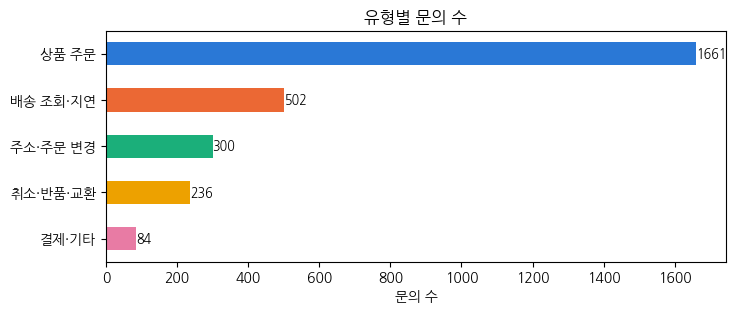

유형
상품 주문       59.7
배송 조회·지연    18.0
주소·주문 변경    10.8
취소·반품·교환     8.5
결제·기타        3.0
Name: proportion, dtype: float64


In [10]:
import matplotlib.pyplot as plt     # 그래프 그리는 도구
import koreanize_matplotlib         # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨

# 유형 순서와 유형별 색 (아래 모든 그래프에서 똑같이 사용)
ORDER = ["상품 주문", "배송 조회·지연", "주소·주문 변경", "취소·반품·교환", "결제·기타"]
COLORS = dict(zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   # {유형: 색} 사전

# 유형별 문의 수 세기 → ORDER 순서로 다시 줄 세우기
counts = data["유형"].value_counts().reindex(ORDER)

# 가로 막대그래프 (figsize: 그림 크기 가로 8, 세로 3)
ax = counts.plot.barh(color=[COLORS[k] for k in ORDER], figsize=(8, 3))
ax.bar_label(ax.containers[0], fontsize=9)       # 막대 끝에 숫자 표시
ax.invert_yaxis()                                # 위에서부터 ORDER 순서대로 보이게 뒤집기
ax.set_xlabel("문의 수")
ax.set_ylabel("")
ax.set_title("유형별 문의 수")
plt.show()

# 유형별 비율(%)도 함께 보기 (normalize=True: 개수 대신 비율)
print((data["유형"].value_counts(normalize=True).reindex(ORDER) * 100).round(1))

✅ **결과 확인:** **상품 주문이 절반 이상**이고 결제·기타는 3%쯤밖에 안 됩니다. 이렇게 유형별 개수 차이가 크면, 모델이 "무조건 상품 주문"이라고만 답해도 정확도가 60%쯤 나옵니다. 그래서 3단계에서는 정확도와 함께 **macro-F1**도 봅니다.

---
## 3. 텍스트 분석: 분류 모델 학습

### 3-1. 학습용 / 평가용 나누기
모델이 **처음 보는 문의**도 잘 맞히는지 확인하려고, 데이터의 20%는 학습에 쓰지 않고 평가용으로 남겨 둡니다.
- `stratify`: 학습용과 평가용의 유형 비율을 똑같이 맞춤 (적은 유형이 한쪽에 몰리지 않게)
- `random_state`: 매번 같은 방식으로 나뉘게 고정 (결과를 다시 확인할 수 있게)

In [11]:
from sklearn.model_selection import train_test_split

# 입력(X) = 단어 목록, 정답(y) = 유형
# test_size=0.2 : 20%를 평가용으로
X_train, X_test, y_train, y_test = train_test_split(
    data["단어"], data["유형"], test_size=0.2, random_state=42, stratify=data["유형"])

print("학습용:", len(X_train), " 평가용:", len(X_test))

학습용: 2226  평가용: 557


### 3-2. TF-IDF로 숫자 바꾸기
| 용어 | 뜻 |
|---|---|
| TF (단어 빈도) | 이 문의에 그 단어가 몇 번 나왔나 |
| IDF (역문서 빈도) | 그 단어가 **여러 문의에 흔하게** 나오면 점수를 낮춤 (`하`, `있` 같은 단어) |
| TF-IDF | 두 값을 곱한 점수 → **이 문의를 특징짓는 단어**일수록 높음 |

> ⚠️ `fit`(단어 사전 만들기)은 **학습용에만** 합니다. 평가용 단어까지 미리 보면 시험 문제를 미리 본 셈이 됩니다.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# analyzer=str.split : 1단계에서 이미 띄어쓰기로 나눠 둔 단어를 그대로 사용 (다시 쪼개지 않음)
tfidf = TfidfVectorizer(analyzer=str.split)

# 학습용: 단어 사전을 만들고(fit) + 숫자 행렬로 바꾸기(transform)
A_train = tfidf.fit_transform(X_train)
# 평가용: 학습용으로 만든 사전으로 바꾸기만 함 (사전에 없는 새 단어는 무시됨)
A_test = tfidf.transform(X_test)

print("단어 사전 크기:", len(tfidf.vocabulary_))
print("학습용 행렬 크기 (문의 수, 단어 수):", A_train.shape)

단어 사전 크기: 1498
학습용 행렬 크기 (문의 수, 단어 수): (2226, 1498)


### 3-3. 분류 모델 3개 비교
| 모델 | 특징 |
|---|---|
| 나이브 베이즈 (`MultinomialNB`) | 단어 확률로 계산하는 빠르고 단순한 모델 (기준선) |
| 로지스틱 회귀 (`LogisticRegression`) | 단어마다 유형별 **가중치**를 배워서 점수를 매김 |
| 로지스틱 회귀 + 균형 (`class_weight="balanced"`) | 개수가 적은 유형을 틀리면 더 크게 벌점을 줌 |

| 평가 지표 | 뜻 |
|---|---|
| 정확도 (accuracy) | 전체 중 맞힌 비율 |
| macro-F1 | 유형마다 F1을 구해 **똑같은 비중으로 평균** → 개수가 적은 유형(결제·기타)도 똑같이 중요하게 봄 |

In [13]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 비교할 모델 3개를 {이름: 모델} 사전으로 준비 (max_iter: 학습 반복 횟수 한도)
models = {
    "나이브 베이즈": MultinomialNB(),
    "로지스틱 회귀": LogisticRegression(max_iter=1000),
    "로지스틱 회귀(균형)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

# 모델마다 학습(fit) → 평가용 예측(predict) → 점수 계산
rows = []                                               # 모델별 점수를 담을 빈 목록
for name, model in models.items():                      # 사전에서 (이름, 모델)을 하나씩 꺼내기
    model.fit(A_train, y_train)                         # 학습용으로 학습
    pred = model.predict(A_test)                        # 평가용 문의의 유형 예측
    rows.append({"모델": name,
                 "정확도": round(accuracy_score(y_test, pred), 3),                     # 소수 셋째 자리까지
                 "macro-F1": round(f1_score(y_test, pred, average="macro"), 3)})

# 목록 → 표
scores = pd.DataFrame(rows)
scores

,모델,정확도,macro-F1
0,나이브 베이즈,0.734,0.373
1,로지스틱 회귀,0.864,0.711
2,로지스틱 회귀(균형),0.855,0.745


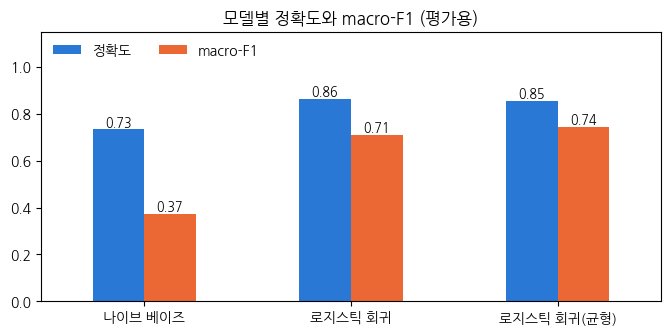

최종 모델: 로지스틱 회귀(균형)


In [14]:
# 정확도와 macro-F1을 모델별로 나란히 그리기 (ylim: 세로축 범위, 위쪽에 범례 자리 남기기)
ax = scores.set_index("모델").plot.bar(color=["#2a78d6", "#eb6834"], figsize=(8, 3.5), rot=0, ylim=(0, 1.15))
for bars in ax.containers:                             # 막대 묶음(정확도, macro-F1)마다
    ax.bar_label(bars, fmt="%.2f", fontsize=9)         # 막대 위에 소수 둘째 자리 숫자 표시
ax.set_xlabel("")
ax.set_title("모델별 정확도와 macro-F1 (평가용)")
ax.legend(loc="upper left", ncol=2, frameon=False)    # 범례를 왼쪽 위에 가로로
plt.show()

# macro-F1이 가장 높은 모델을 최종 모델로 선택
#   sort_values(ascending=False) : 큰 값부터 정렬 → 첫 줄 ["모델"] 이름 꺼내기
best_name = scores.sort_values("macro-F1", ascending=False)["모델"].iloc[0]
best = models[best_name]
print("최종 모델:", best_name)

✅ **결과 확인:** 나이브 베이즈는 정확도에 비해 macro-F1이 매우 낮습니다. 개수가 많은 '상품 주문' 쪽으로 쏠려서 **적은 유형을 거의 못 맞히기** 때문입니다. 정확도가 가장 높은 모델과 macro-F1이 가장 높은 모델이 같은가요? 다르다면 **무엇을 기준으로 고를지**는 업무 목적에 달려 있습니다(정리 참고).

---
## 4. 분석 결과
| 번호 | 결과 |
|---|---|
| 4-1 | 유형별 성적표 (정밀도·재현율·F1) |
| 4-2 | 혼동 행렬: 어떤 유형을 어떤 유형으로 헷갈렸나 |
| 4-3 | 유형별 핵심 단어 |
| 4-4 | 틀린 문의 직접 읽기 |
| 4-5 | 새 문의 넣어 보기 |

### 4-1. 유형별 성적표
| 지표 | 뜻 (예: 배송 조회·지연) |
|---|---|
| 정밀도 (precision) | 모델이 '배송 조회·지연'이라고 한 것 중 진짜 배송 조회·지연 비율 |
| 재현율 (recall) | 진짜 배송 조회·지연 중 모델이 찾아낸 비율 |
| F1 | 정밀도와 재현율의 조화 평균 |
| support | 평가용에 있는 그 유형의 문의 수 |

In [15]:
from sklearn.metrics import classification_report

# 최종 모델로 평가용 문의 예측
pred = best.predict(A_test)

# 유형별 성적표 (labels=ORDER: 유형 순서 고정, digits=3: 소수 셋째 자리)
print(classification_report(y_test, pred, labels=ORDER, digits=3))

              precision    recall  f1-score   support

       상품 주문      0.942     0.880     0.910       332
    배송 조회·지연      0.852     0.911     0.880       101
    주소·주문 변경      0.639     0.767     0.697        60
    취소·반품·교환      0.826     0.809     0.817        47
       결제·기타      0.381     0.471     0.421        17

    accuracy                          0.855       557
   macro avg      0.728     0.767     0.745       557
weighted avg      0.866     0.855     0.859       557



### 4-2. 혼동 행렬

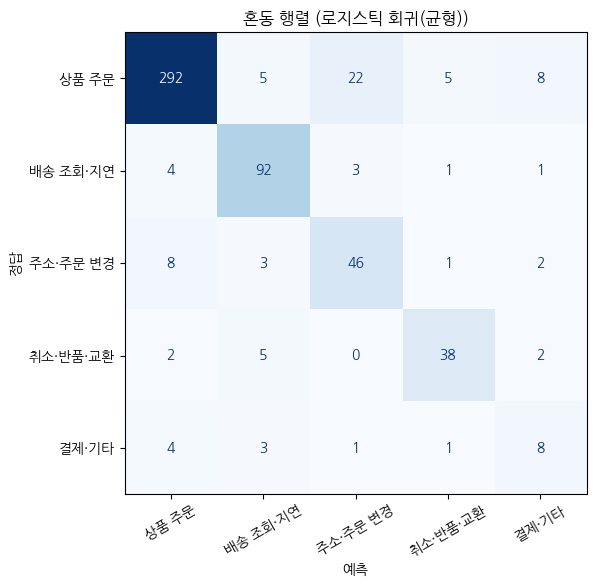

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

# 그림판 준비 (fig: 그림 전체, ax: 그래프 한 칸)
fig, ax = plt.subplots(figsize=(7, 6))

# 가로 = 모델 예측, 세로 = 정답, 대각선 = 맞힌 문의 수
#   cmap="Blues" : 숫자가 클수록 진한 파랑
#   colorbar=False : 오른쪽 색 막대 숨기기
#   xticks_rotation=30 : 가로축 글자를 30도 기울여 겹치지 않게
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=ORDER, cmap="Blues",
                                        colorbar=False, ax=ax, xticks_rotation=30)
ax.set_xlabel("예측")
ax.set_ylabel("정답")
ax.set_title(f"혼동 행렬 ({best_name})")
plt.show()

✅ **결과 확인:** 대각선이 아닌 칸 중 숫자가 큰 곳을 찾아보세요. '상품 주문'과 '주소·주문 변경' 사이 칸에 숫자가 크다면, "주문하려는데 주소가 바뀌었어요"(새 주문)와 "주문했는데 주소를 바꾸고 싶어요"(변경)처럼 **쓰는 단어가 거의 같은 문의** 때문일 수 있습니다. '결제·기타'는 문의 수가 적어서 맞힌 개수도 적습니다.

### 4-3. 유형별 핵심 단어
로지스틱 회귀는 단어마다 유형별 **가중치**를 배웁니다. 가중치가 클수록 그 유형이라고 판단하는 데 크게 쓰인 단어입니다.

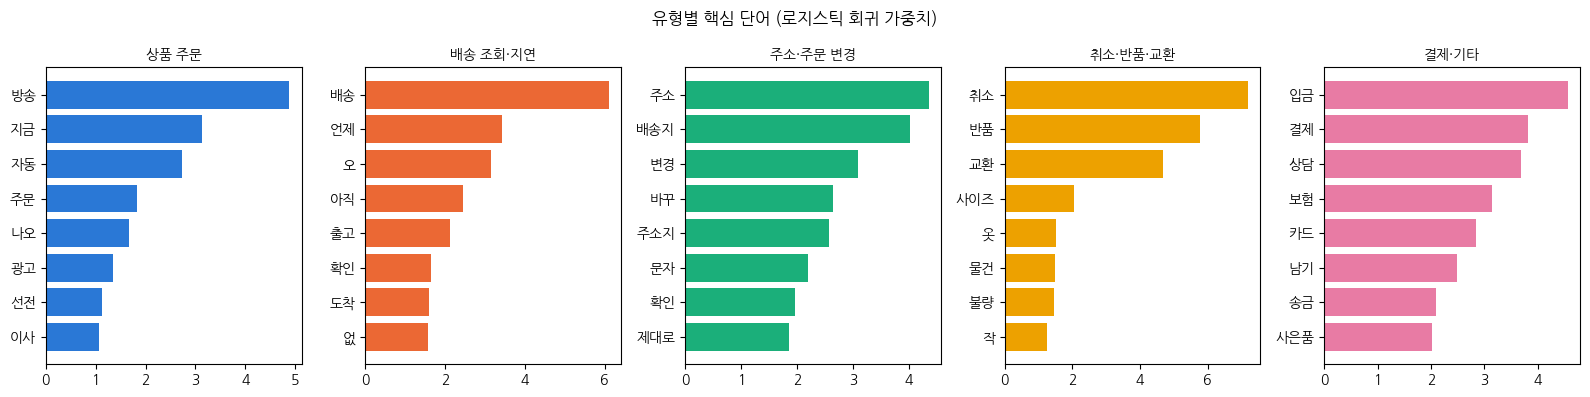

In [17]:
# 단어 사전의 단어들 (가중치와 같은 순서로 들어 있음)
words = tfidf.get_feature_names_out()

# 핵심 단어를 볼 모델 (최종 모델에 가중치 coef_가 없으면, 즉 나이브 베이즈면 로지스틱 회귀로 대신 봄)
lr = best if hasattr(best, "coef_") else models["로지스틱 회귀"]

# 유형 5개 → 그래프 칸 5개를 가로로
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, k in zip(axes, ORDER):                             # (그래프 칸, 유형)을 하나씩 짝지어 꺼내기
    weights = lr.coef_[list(lr.classes_).index(k)]         # 유형 k의 단어별 가중치 한 줄
    top = weights.argsort()[::-1][:8]                      # 가중치가 큰 순서로 단어 위치 8개
    ax.barh(words[top][::-1], weights[top][::-1], color=COLORS[k])   # [::-1]: 큰 값이 위로 오게 뒤집기
    ax.set_title(k, fontsize=10)
fig.suptitle("유형별 핵심 단어 (로지스틱 회귀 가중치)")
plt.tight_layout()                                         # 칸끼리 글자가 겹치지 않게 간격 자동 조정
plt.show()

✅ **결과 확인:** 사람이 봐도 그 유형다운 단어인가요? `반품`, `교환`, `언제`, `주소`처럼 당연한 단어도 있지만, 상품 주문의 `방송`, `지금`처럼 **홈쇼핑에서만 통하는 표현**도 보입니다. 상품 주문에 `이사` 같은 단어가 보인다면, "주문하려는데 이사해서 주소가 바뀌었어요"라는 말이 많았기 때문입니다. 이런 단어는 다른 쇼핑몰 데이터에서는 잘 통하지 않을 수 있습니다.

### 4-4. 틀린 문의 직접 읽기

In [18]:
# 평가용 문의의 원래 정보(ID, 질문, 정답)에 예측을 붙인 표
#   X_test.index : 평가용 문의가 data 표의 몇 번째 줄인지
#   assign(예측=pred) : '예측' 열 추가
result = data.loc[X_test.index, ["ID", "질문", "유형"]].assign(예측=pred)

# 정답과 예측이 다른 줄만 고르기
wrong = result[result["유형"] != result["예측"]]
print(f"틀린 문의: {len(wrong)}개 / {len(result)}개")

# 긴 질문도 80글자까지 보이게 설정한 뒤 앞 10개 보기
pd.set_option("display.max_colwidth", 80)
wrong.head(10)

틀린 문의: 81개 / 557개


,ID,질문,유형,예측
1749,S10557,아 안녕하세요. 이십며칠 날 우리가 주문을 했거든요 그런데 두 번이나 드로즈로 와서요.,취소·반품·교환,배송 조회·지연
962,S14443,네. 뭐 좀 여쭤 보겠습니다. 네. 아까 오전에 홈쇼핑에서 샀던 건데요. 명절 선물로 다른 곳으로 보내고 싶으면 주소를 그쪽에 보내야 하나요?,주소·주문 변경,상품 주문
508,S16691,아 전화를 주셨는데 전화를 못 받아 그렇군요? 네 문자로 그렇게 하시지 누가 그 번호로 전화를 받아요? 전화는 오지도 않았는데?,상품 주문,배송 조회·지연
1685,S10922,주문해서 보내려고 하는데 상담 좀 하려구요. 네. 뭐 불러주면 됩니까?,상품 주문,결제·기타
1395,S12424,제가 저기 에 가입이 안돼있는데 지금 주문할려고요. 제가 선물로 보낼거니까 주소는 다르게 신청해 주세요.,상품 주문,주소·주문 변경
2676,S1200,방송중으로 자켓 지금 파는 거 있죠? 혹시 사이즈가 안 맞으면 반품이나 교환이 됩니까?,상품 주문,취소·반품·교환
1778,S10346,티셔츠가 왔는데요. 옷 사이즈가 하나하나가 다 틀린 게 와서요 확인하려고 전화했거든요. 전화번호가 요.,취소·반품·교환,배송 조회·지연
1202,S13244,아 네 제가 그 에어컨 커버 오늘 받았는데. 제가 그레이 색깔로 주문했는데 하얀 색이 왔어요.,취소·반품·교환,결제·기타
40,S19617,혹시 저희가 거기 있나 좀 알아봐 주시겠어요? 핸드폰 이거고요. 이름은 .,결제·기타,배송 조회·지연
2673,S1207,아 네 지금 티비하는 거 신청하면 언제 받아 볼 수 있어요? 아 명절 때 받을 수 있어요? 그걸로 보낼려고 하는 건데요?,상품 주문,취소·반품·교환


✅ **결과 확인:** 틀린 이유를 세 가지로 나눠 보세요.
1. **모델이 틀림** (질문에 유형을 알 수 있는 단어가 있는데 틀림)
2. **질문 2마디만으로는 알 수 없음** ("지금 방송하는 거요. 네 그래요.")
3. **정답이 의심스러움** (사람이 정한 정답이 틀렸을 수도 있음)

### 4-5. 새 문의 넣어 보기
**✏️ [입력]** 문의 문장을 바꿔 보세요. 유형별 확률이 함께 나옵니다.

In [19]:
# ===== ✏️ [입력] 새 문의 =====
new_questions = [
    "지금 방송하는 갈비 주문하려고요",
    "지난주에 주문했는데 아직도 안 왔어요",
    "어제 주문한 거 배송지를 바꾸고 싶어요",
    "신발이 작아서 한 사이즈 큰 걸로 교환하고 싶어요",
    "무통장 입금했는데 확인이 안 된다고 나와요",
]
# ============================

# 새 문의도 학습 때와 같은 방법으로 단어 나누기 → TF-IDF 숫자로 바꾸기 (fit 없이 transform만)
A_new = tfidf.transform([to_words(q) for q in new_questions])

# 유형별 확률 표 (행 = 문의, 열 = 유형, 값 = %)
#   predict_proba : 유형마다 0~1 확률 → ×100 해서 %
#   columns=best.classes_ : 모델이 기억하는 유형 순서로 열 이름 붙이기 → [ORDER] 순서로 다시 줄 세우기
proba = pd.DataFrame(best.predict_proba(A_new) * 100, columns=best.classes_, index=new_questions)[ORDER].round(1)

# 확률이 가장 큰 유형(idxmax)을 맨 앞 열에 끼워 넣기
proba.insert(0, "예측 유형", proba.idxmax(axis=1))
proba

,예측 유형,상품 주문,배송 조회·지연,주소·주문 변경,취소·반품·교환,결제·기타
지금 방송하는 갈비 주문하려고요,상품 주문,99.2,0.1,0.2,0.1,0.3
지난주에 주문했는데 아직도 안 왔어요,배송 조회·지연,3.9,77.5,4.5,11.1,3.0
어제 주문한 거 배송지를 바꾸고 싶어요,주소·주문 변경,0.7,0.5,97.0,1.1,0.7
신발이 작아서 한 사이즈 큰 걸로 교환하고 싶어요,취소·반품·교환,1.8,0.4,0.4,96.5,0.8
무통장 입금했는데 확인이 안 된다고 나와요,결제·기타,1.3,6.1,3.1,1.4,88.0


### 결과 저장

In [20]:
# 평가용 문의별 정답과 예측 저장 (엑셀에서 열면 틀린 문의를 걸러 볼 수 있음)
result.to_csv("predictions.csv", index=False, encoding="utf-8-sig")
print("저장 완료: inquiry_dataset.csv, predictions.csv")

저장 완료: inquiry_dataset.csv, predictions.csv


---
## 정리

### ✅ 한 줄 정리
**고객이 처음 꺼낸 말 두 마디를 단어로 나누고 TF-IDF 숫자로 바꾼 뒤, 분류 모델이 문의 유형을 맞히도록 학습시켰다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `inquiry_dataset.csv` | 정제 데이터셋 (ID, 질문, 단어, 유형) |
| `predictions.csv` | 평가용 문의의 정답과 예측 |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **정답이 사람 한 명의 판단** | 키워드로 임시 정답을 만들고 한 사람이 고쳤습니다. 여러 사람이 정답을 달고 일치하는지 확인하는 것이 더 믿을 만합니다. |
| **유형 기준에 정답이 없음** | "배송이 너무 늦어서 취소하려고요"는 배송 조회·지연일까요, 취소·반품·교환일까요? 이번에는 '고객이 원하는 처리(취소)'를 기준으로 했지만, 회사마다 기준이 다를 수 있습니다. |
| **상품 주문이 너무 많음** | 전체의 절반 이상이 상품 주문이라 모델이 상품 주문 쪽으로 쏠리기 쉽습니다. 결제·기타는 평가용에 20건도 안 돼서 점수가 조금만 바뀌어도 크게 흔들립니다. |
| **2마디 vs 1마디** | 같은 방식으로 시험해 보니, 첫 질문 1마디만 쓰면 정확도·macro-F1이 모두 떨어졌습니다. 다만 2마디를 기다리면 그만큼 연결이 늦어집니다. |
| **정확도 vs macro-F1** | 많이 들어오는 문의를 잘 맞히는 게 중요하면 정확도, 적게 들어오는 유형도 놓치면 안 되면 macro-F1을 기준으로 고릅니다. |



**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn 텍스트 특징 추출](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [scikit-learn 분류 평가](https://scikit-learn.org/stable/modules/model_evaluation.html)